<a href="https://colab.research.google.com/github/chartie87742/marketing-analytics-carlos-garciagranados/blob/main/Semana_6/Laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab · Segmentación de clientes
**Pregunta de negocio:** ¿a qué grupos de clientes les hablamos distinto, y cuánto vale cada grupo?

Este notebook replica en Python, paso por paso, el lab diseñado para Orange. Cada sección indica **qué widget de Orange reemplaza** y **por qué** se hace.

| Parte | Qué se hace | Equivalente Orange |
|---|---|---|
| 0 | Cargar datos | File |
| 1 | Conocer los datos | Data Table, Distributions |
| 2 | k-means | Select Columns, Normalize, k-Means, Scatter Plot, Group By |
| 3 | Comparar técnicas | Distances, Hierarchical Clustering, DBSCAN |
| 4 | Valor por segmento + guardar | Group By, Formula, Save Data |
| 5 | Cuando k-means falla | k-Means / DBSCAN sobre `formas_lunas.csv` |

> **Cómo usarlo:** ejecute las celdas en orden (`Shift + Enter`). Las respuestas están en las celdas marcadas con ✍️.

## 0 · Preparar el entorno y cargar los archivos

**Qué hace la celda siguiente:**
1. Busca los CSV en la sesión de Colab.
2. Si no están, intenta clonar su repositorio de GitHub (funciona si el repo es **público**).
3. Si tampoco, le abre un cuadro para **subir los archivos** desde su computadora.

> Importante: abrir un notebook desde GitHub en Colab **no** trae los demás archivos del repo. Colab arranca en una máquina vacía; por eso hay que clonar o subir los datos.

👉 Si sus CSV están en otra carpeta del repo, cambie `CARPETA`.

In [4]:
import os, subprocess

REPO    = "chartie87742/marketing-analytics-carlos-garciagranados"
CARPETA = "Semana_6/lab_segmentacion" # carpeta del repo donde está /data
ARCHIVOS = ["clientes_retail.csv", "formas_lunas.csv"]

def buscar(nombre):
    candidatos = [nombre, f"data/{nombre}", f"{CARPETA}/data/{nombre}",
                  f"/content/repo/{CARPETA}/data/{nombre}", f"/content/repo/data/{nombre}",
                  f"/content/repo/{nombre}"]
    return next((c for c in candidatos if os.path.exists(c)), None)

faltan = [a for a in ARCHIVOS if buscar(a) is None]

if faltan and not os.path.exists("/content/repo"):
    os.environ["GIT_TERMINAL_PROMPT"] = "0"   # si el repo es privado, falla rápido en vez de quedarse esperando
    r = subprocess.run(["git", "clone", "--depth", "1", f"https://github.com/{REPO}.git", "/content/repo"],
                       capture_output=True, text=True)
    print("Clonado del repo:", "OK" if r.returncode == 0 else "no se pudo (¿repo privado?)")
    faltan = [a for a in ARCHIVOS if buscar(a) is None]

if faltan:
    try:
        from google.colab import files
        print("Suba estos archivos:", faltan)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"No encuentro {faltan}. Póngalos en la carpeta data/.")

RUTA = {a: buscar(a) for a in ARCHIVOS}
RUTA

{'clientes_retail.csv': '/content/repo/Semana_6/lab_segmentacion/data/clientes_retail.csv',
 'formas_lunas.csv': '/content/repo/Semana_6/lab_segmentacion/data/formas_lunas.csv'}

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import joblib

def limpiar_encabezados(df):
    """Los CSV vienen en formato Orange: el encabezado lleva un prefijo con el rol de la columna.
    m# = meta, D# = discreta, C# = continua (ej. 'mD#respondio_ultima_campana').
    Pandas no los entiende, así que quitamos el prefijo y dejamos solo el nombre."""
    df.columns = df.columns.str.replace(r"^[A-Za-z]{0,3}#", "", regex=True)
    return df

SEMILLA = 42                     # fija el azar para que k-means dé siempre el mismo resultado
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams["figure.dpi"] = 110
COLORES = {"C1": "#4C78A8", "C2": "#F58518", "C3": "#54A24B"}

## Parte 1 · Conozca los datos (≈10 min)
**Orange:** `File → Data Table` y `Distributions (gasto_total)`.

Primero miramos la tabla: cuántas filas y columnas, de qué tipo es cada columna y si hay vacíos.

> Los CSV traen encabezados de Orange (`m#id_cliente`, `D#educacion`, `mD#respondio_ultima_campana`). La función `limpiar_encabezados` quita esos prefijos.

In [6]:
clientes = limpiar_encabezados(pd.read_csv(RUTA["clientes_retail.csv"]))
print("Filas x columnas:", clientes.shape)
display(clientes.head())
clientes.info()

Filas x columnas: (2205, 23)


,id_cliente,ingreso_anual,edad,hijos_pequenos,hijos_adolescentes,dias_como_cliente,recencia_dias,gasto_vinos,gasto_frutas,gasto_carnes,...,gasto_total,compras_oferta,compras_web,compras_catalogo,compras_tienda,visitas_web_mes,campanas_aceptadas,educacion,estado_civil,respondio_ultima_campana
0,1,58138,63,0,0,2822,58,635,88,546,...,1529,3,8,10,4,7,0,Licenciatura,Soltero,1
1,2,46344,66,1,1,2272,38,11,1,6,...,21,2,1,1,2,5,0,Licenciatura,Soltero,0
2,3,71613,55,0,0,2471,26,426,49,127,...,734,1,8,2,10,4,0,Licenciatura,Union_libre,0
3,4,26646,36,1,0,2298,26,11,4,20,...,48,2,2,0,4,6,0,Licenciatura,Union_libre,0
4,5,58293,39,1,0,2320,94,173,43,118,...,407,5,5,3,6,5,0,Doctorado,Casado,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   id_cliente                2205 non-null   int64 
 1   ingreso_anual             2205 non-null   int64 
 2   edad                      2205 non-null   int64 
 3   hijos_pequenos            2205 non-null   int64 
 4   hijos_adolescentes        2205 non-null   int64 
 5   dias_como_cliente         2205 non-null   int64 
 6   recencia_dias             2205 non-null   int64 
 7   gasto_vinos               2205 non-null   int64 
 8   gasto_frutas              2205 non-null   int64 
 9   gasto_carnes              2205 non-null   int64 
 10  gasto_pescado             2205 non-null   int64 
 11  gasto_dulces              2205 non-null   int64 
 12  gasto_premium             2205 non-null   int64 
 13  gasto_total               2205 non-null   int64 
 14  compras_oferta          

In [7]:
display(clientes.describe().T)   # media, desviación, mínimo, percentiles y máximo de cada columna

,count,mean,std,min,25%,50%,75%,max
id_cliente,"2,205.00","1,103.00",636.67,1.00,552.00,"1,103.00","1,654.00","2,205.00"
ingreso_anual,"2,205.00","51,622.09","20,713.06","1,730.00","35,196.00","51,287.00","68,281.00","113,734.00"
edad,"2,205.00",51.10,11.71,24.00,43.00,50.00,61.00,80.00
hijos_pequenos,"2,205.00",0.44,0.54,0.00,0.00,0.00,1.00,2.00
hijos_adolescentes,"2,205.00",0.51,0.54,0.00,0.00,0.00,1.00,2.00
dias_como_cliente,"2,205.00","2,512.72",202.56,"2,159.00","2,339.00","2,515.00","2,688.00","2,858.00"
recencia_dias,"2,205.00",49.01,28.93,0.00,24.00,49.00,74.00,99.00
gasto_vinos,"2,205.00",306.16,337.49,0.00,24.00,178.00,507.00,"1,493.00"
gasto_frutas,"2,205.00",26.40,39.78,0.00,2.00,8.00,33.00,199.00
gasto_carnes,"2,205.00",165.31,217.78,0.00,16.00,68.00,232.00,"1,725.00"


### Distribución de `gasto_total`
Equivale a `Distributions`. Además del histograma calculamos tres cosas que Orange no muestra directamente:
- **Media vs. mediana:** si la media es bastante mayor que la mediana, unos pocos clientes grandes jalan el promedio hacia arriba.
- **Asimetría (skew):** > 1 indica cola larga a la derecha.
- **Concentración:** qué % del gasto aporta el 20 % de clientes que más gasta (la lógica de Pareto).

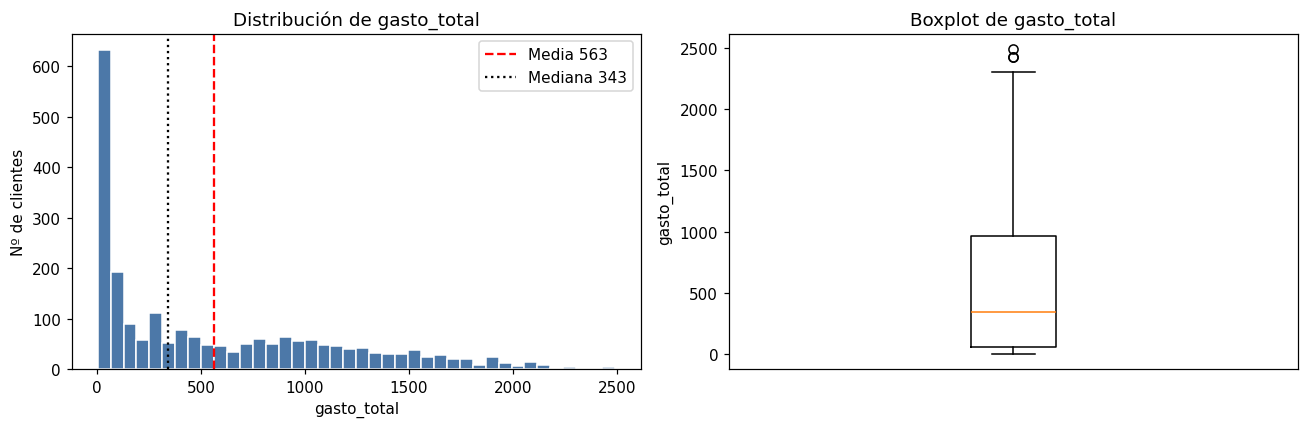

Media: 563 | Mediana: 343 | Asimetría: 0.92
El 20% de clientes que más gasta genera el 54% del gasto total


In [8]:
g = clientes["gasto_total"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(g, bins=40, color="#4C78A8", edgecolor="white")
ax[0].axvline(g.mean(),   color="red",   ls="--", label=f"Media {g.mean():,.0f}")
ax[0].axvline(g.median(), color="black", ls=":",  label=f"Mediana {g.median():,.0f}")
ax[0].set(title="Distribución de gasto_total", xlabel="gasto_total", ylabel="Nº de clientes"); ax[0].legend()
ax[1].boxplot(g); ax[1].set(title="Boxplot de gasto_total", ylabel="gasto_total", xticks=[])
plt.tight_layout(); plt.show()

top20 = g.sort_values(ascending=False).head(int(len(g) * 0.20)).sum() / g.sum()
print(f"Media: {g.mean():,.0f} | Mediana: {g.median():,.0f} | Asimetría: {g.skew():.2f}")
print(f"El 20% de clientes que más gasta genera el {top20:.0%} del gasto total")

✍️ **Respuesta Parte 1 — ¿Cómo se ve `gasto_total`?**

La distribución está **sesgada a la derecha**: muchos clientes gastan poco y unos pocos gastan mucho. La media (563) es bastante mayor que la mediana (343), la asimetría es de 0.92 y **el 20 % de clientes que más gasta genera el 54 % del gasto total**.

> **Implicación técnica:** k-means usa promedios, y los promedios se dejan jalar por los extremos. Con una variable así de sesgada, los clientes "grandes" tienden a definir su propio grupo. Una mejora habitual sería aplicar logaritmo a `gasto_total` e `ingreso_anual` antes de agrupar.

## Parte 2 · k-means: el punto de partida (≈15 min)

### 2.1 Seleccionar atributos — `Select Columns`
Solo entran al algoritmo las 9 variables que pide la guía. Las demás (gasto por categoría, `gasto_premium`, respuesta a campaña…) quedan fuera del cálculo pero **siguen en la tabla** para describir los grupos después (eso es lo que Orange llama *Meta*).

¿Por qué dejar fuera `respondio_ultima_campana`? Porque es lo que queremos **explicar** con los segmentos; si la metemos en el agrupamiento, el resultado se vuelve circular.

In [9]:
ATRIBUTOS = ["ingreso_anual", "gasto_total", "compras_tienda", "compras_web", "compras_catalogo",
             "visitas_web_mes", "recencia_dias", "hijos_pequenos", "edad"]

faltantes = [c for c in ATRIBUTOS if c not in clientes.columns]
assert not faltantes, f"Revise nombres de columnas: {faltantes}"

X = clientes[ATRIBUTOS]
print("Valores vacíos en los atributos:", int(X.isna().sum().sum()))

Valores vacíos en los atributos: 0


### 2.2 Estandarizar — `Normalize` (Standardize μ=0, σ²=1)
k-means mide **distancias**. Si no estandarizamos, una diferencia de 10,000 en ingreso pesa muchísimo más que una diferencia de 5 visitas web, y el algoritmo prácticamente solo "ve" ingreso y gasto.

Estandarizar = a cada valor se le resta la media de su columna y se divide entre la desviación estándar (z-score). Así todas las variables quedan en la misma escala: 0 = promedio, +1 = una desviación por encima.

In [10]:
escalador = StandardScaler()
Xz = escalador.fit_transform(X)

# Verificación: todas las columnas deben tener media 0 y desviación 1
display(pd.DataFrame(Xz, columns=ATRIBUTOS).agg(["mean", "std"]).round(2))

,ingreso_anual,gasto_total,compras_tienda,compras_web,compras_catalogo,visitas_web_mes,recencia_dias,hijos_pequenos,edad
mean,0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


### 2.3 ¿Cuántos grupos? — `k-Means` "From 2 to 8"
Probamos k = 2…8 y para cada uno calculamos:
- **Silueta (silhouette):** para cada cliente compara qué tan cerca está de su propio grupo vs. del grupo vecino. Va de −1 a 1. Referencia común: > 0.50 estructura fuerte; 0.25–0.50 moderada/débil; < 0.25 casi no hay grupos naturales.
- **Inercia (método del codo):** suma de distancias al centro del grupo. Siempre baja al subir k; buscamos el "codo".

`n_init=10` = corre k-means 10 veces con centros iniciales distintos y se queda con el mejor (Orange también reinicia varias veces).

,silueta,inercia
k,,
2,0.343,"12,109"
3,0.251,"10,656"
4,0.193,"9,789"
5,0.171,"9,148"
6,0.163,"8,607"
7,0.161,"8,229"
8,0.165,"7,865"


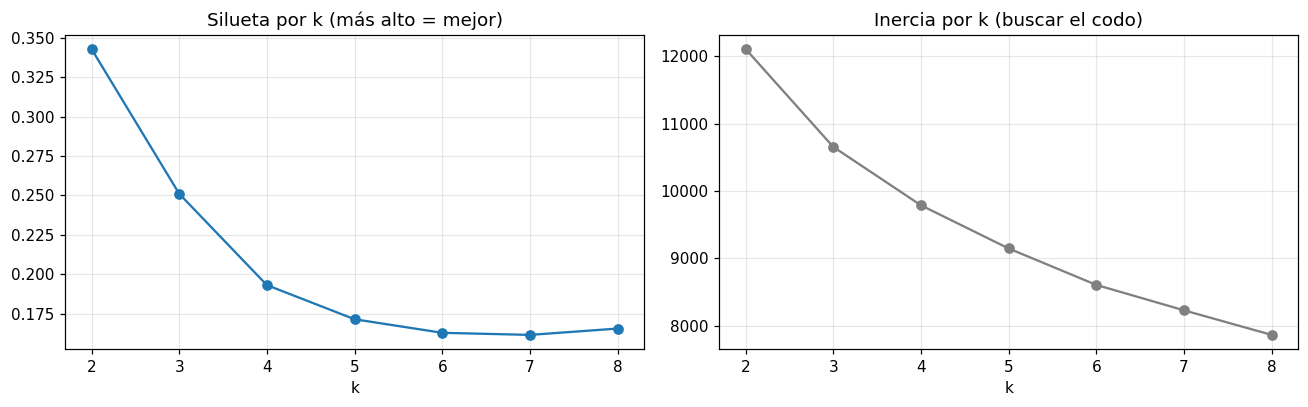

Mejor silueta: k = 2 (0.343)


In [11]:
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xz)
    filas.append({"k": k, "silueta": silhouette_score(Xz, km.labels_), "inercia": km.inertia_})
tabla_k = pd.DataFrame(filas).set_index("k")
display(tabla_k.style.highlight_max(subset="silueta", color="#d4edda").format({"silueta": "{:.3f}", "inercia": "{:,.0f}"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
tabla_k["silueta"].plot(ax=ax[0], marker="o", title="Silueta por k (más alto = mejor)")
tabla_k["inercia"].plot(ax=ax[1], marker="o", color="gray", title="Inercia por k (buscar el codo)")
for a in ax: a.set_xlabel("k"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"Mejor silueta: k = {tabla_k['silueta'].idxmax()} ({tabla_k['silueta'].max():.3f})")

### 2.4 Fijar k = 3 y nombrar los grupos C1, C2, C3
k-means numera los grupos al azar (0, 1, 2). Para que el resultado sea **estable y legible**, los reordenamos por gasto promedio: **C1 = menor gasto, C3 = mayor gasto**.

> Sus etiquetas en Orange pueden quedar en otro orden. Lo que importa es el **perfil** de cada grupo, no el número.

In [12]:
K = 3
km3 = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(Xz)

orden = clientes.groupby(km3.labels_)["gasto_total"].mean().sort_values().index
MAPA = {original: f"C{i+1}" for i, original in enumerate(orden)}
clientes["Cluster"] = pd.Series(km3.labels_).map(MAPA).values

print(f"Silueta con k=3: {silhouette_score(Xz, km3.labels_):.3f}")
clientes["Cluster"].value_counts().sort_index()

Silueta con k=3: 0.251


,count
Cluster,
C1,1013
C2,631
C3,561


### 2.5 Scatter Plot — x = ingreso_anual, y = gasto_total, color = Cluster

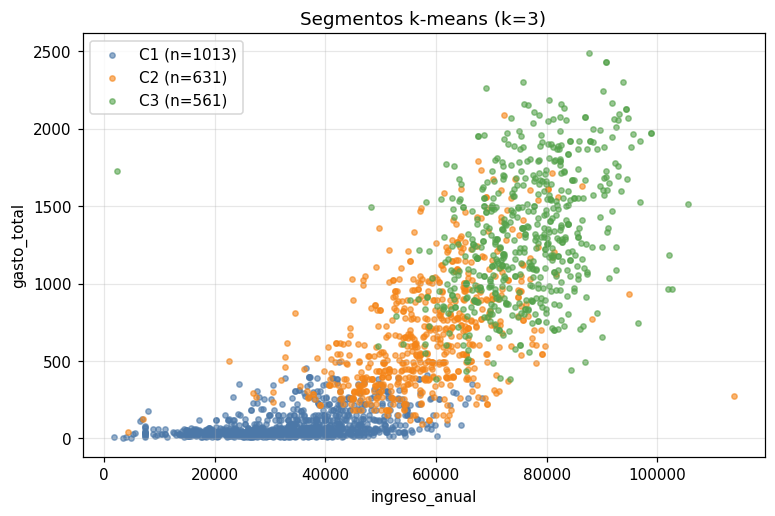

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for c in sorted(clientes["Cluster"].unique()):
    s = clientes[clientes["Cluster"] == c]
    ax.scatter(s["ingreso_anual"], s["gasto_total"], s=12, alpha=.6, label=f"{c} (n={len(s)})", color=COLORES[c])
ax.set(xlabel="ingreso_anual", ylabel="gasto_total", title="Segmentos k-means (k=3)")
ax.legend(); ax.grid(alpha=.3); plt.show()

### 2.6 Perfil de cada segmento — `Group By` (promedio por Cluster)
La primera tabla muestra el **promedio real** de cada variable. La segunda es un **índice vs. el promedio de todos los clientes** (100 = igual al promedio; 150 = 50 % arriba; 60 = 40 % abajo). El índice es lo que más ayuda a ponerle nombre de negocio a cada grupo.

In [14]:
EXTRA = [c for c in ["gasto_premium", "respondio_ultima_campana"] if c in clientes.columns]
if "respondio_ultima_campana" in clientes and clientes["respondio_ultima_campana"].dtype == object:
    clientes["respondio_ultima_campana"] = (clientes["respondio_ultima_campana"].astype(str).str.strip().str.lower()
                                            .isin(["1", "si", "sí", "yes", "true"]).astype(int))

perfil = clientes.groupby("Cluster")[ATRIBUTOS + EXTRA].mean()
perfil.insert(0, "n_clientes", clientes["Cluster"].value_counts().sort_index())
display(perfil.T)

indice = (clientes.groupby("Cluster")[ATRIBUTOS].mean() / clientes[ATRIBUTOS].mean() * 100).round(0)
display(indice.T.style.background_gradient(cmap="RdYlGn", axis=1).format("{:.0f}"))

Cluster,C1,C2,C3
n_clientes,"1,013.00",631.00,561.00
ingreso_anual,"33,985.62","58,158.72","76,116.10"
gasto_total,85.39,670.37,"1,303.74"
compras_tienda,3.21,7.55,8.59
compras_web,2.19,6.47,4.89
compras_catalogo,0.56,2.84,6.19
visitas_web_mes,6.60,5.71,2.63
recencia_dias,49.09,46.12,52.12
hijos_pequenos,0.84,0.17,0.03
edad,47.75,55.84,51.79


Cluster,C1,C2,C3
ingreso_anual,66,113,147
gasto_total,15,119,232
compras_tienda,55,130,148
compras_web,53,158,119
compras_catalogo,21,107,234
visitas_web_mes,124,107,49
recencia_dias,100,94,106
hijos_pequenos,190,39,7
edad,93,109,101


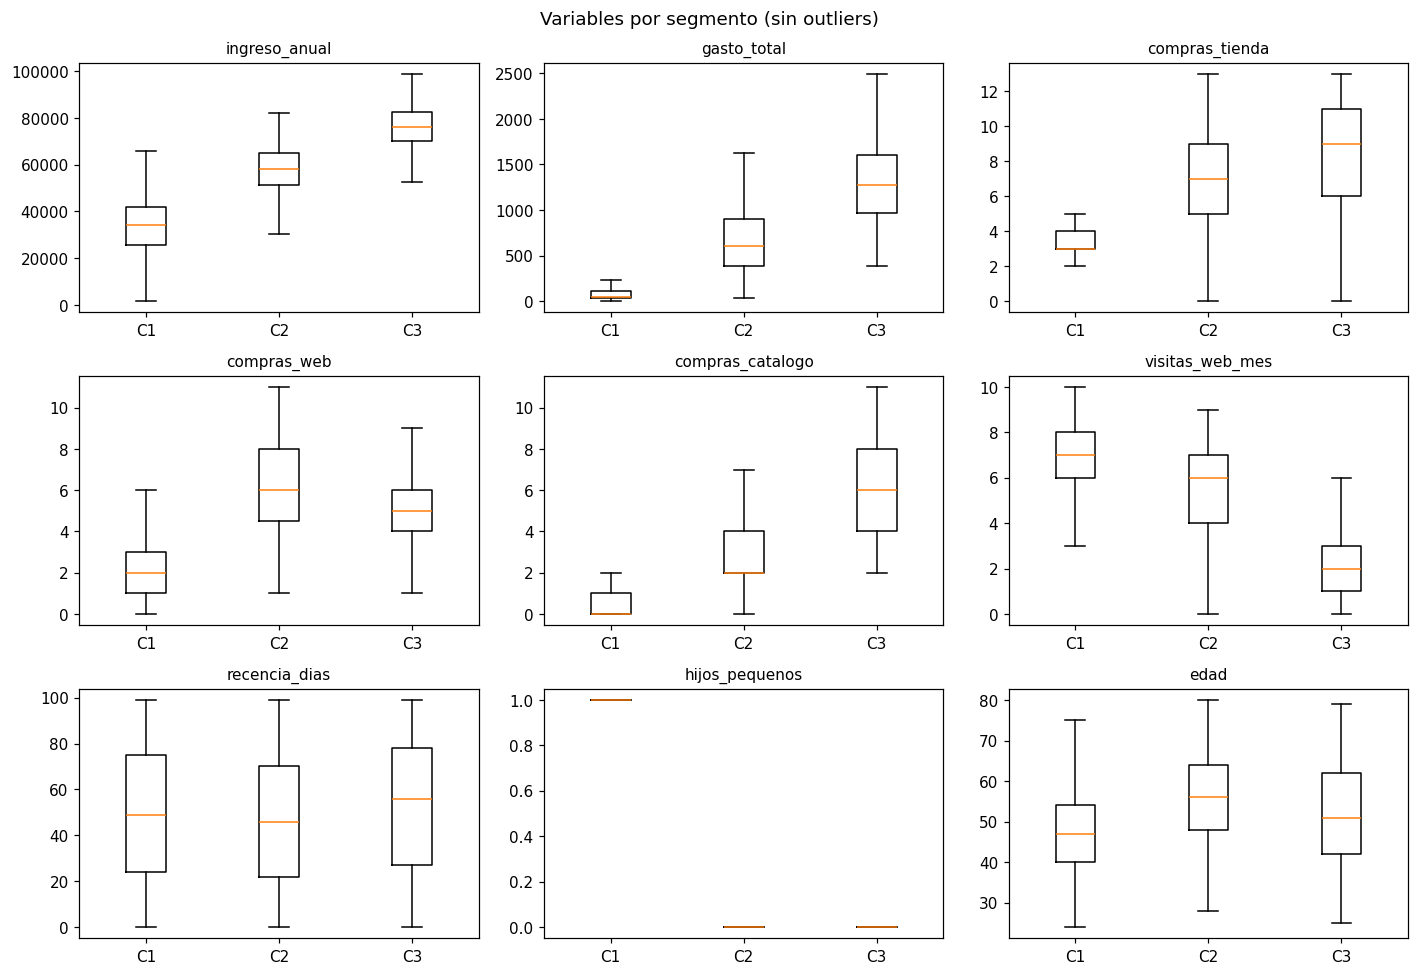

In [15]:
# Equivalente a Box Plot por Cluster: la mediana y la dispersión de cada variable por segmento
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ATRIBUTOS):
    datos = [clientes.loc[clientes["Cluster"] == c, col] for c in sorted(clientes["Cluster"].unique())]
    ax.boxplot(datos, showfliers=False)
    ax.set_xticks(range(1, len(datos) + 1), sorted(clientes["Cluster"].unique()))
    ax.set_title(col, fontsize=10)
plt.suptitle("Variables por segmento (sin outliers)"); plt.tight_layout(); plt.show()

✍️ **Respuestas Parte 2**

1. **¿Qué k tiene mejor silueta?**
k = 2, con silueta = 0.343. La silueta baja de forma continua al subir k (k=3: 0.251; k=4: 0.193; de k=5 a k=8: 0.16–0.17). No hay un k claramente superior después de 2.
Aun así trabajamos con **k = 3**: k = 2 solo separa "gasta mucho / gasta poco", mientras que k = 3 agrega un segmento intermedio con un comportamiento distinto (omnicanal y de ofertas), que es accionable para marketing. Cambiamos algo de separación estadística por utilidad de negocio.

2. **¿Es muy alta?**
No. 0.343 es una estructura moderada-débil, y con k = 3 (0.251) queda en el límite entre débil y moderada. Los clientes forman una nube continua y los grupos se traslapan. La segmentación es una **partición útil para decidir**, no un reflejo de grupos naturales bien separados.

3. **Nombre de negocio por segmento** (índice 100 = promedio de todos los clientes):
- **C1 · Familias jóvenes sensibles al precio** (1,013 clientes, 46 %): ingreso de 34 mil (índice 66) y gasto de 85 (índice 15). El 80 % tiene hijos pequeños. Visitan mucho la web (6.6 visitas/mes, índice 124), pero compran poco ahí (2.2 compras): **navegan sin convertir**. Respuesta a la última campaña: 10 %.
- **C2 · Familias establecidas omnicanal** (631 clientes, 29 %): ingreso de 58 mil (índice 113) y gasto de 670 (índice 119). Son el grupo de mayor edad (56 años) y el que más hijos adolescentes tiene. Son los que **más compran por web** (6.5, índice 158), compran mucho en tienda y son los que más usan ofertas (3.3 compras con descuento). Respuesta: 14 %.
- **C3 · Premium de alto valor por catálogo** (561 clientes, 25 %): ingreso de 76 mil (índice 147) y gasto de 1,304 (índice 232). Casi sin hijos pequeños (3 %). Son los que **más compran por catálogo** (6.2, índice 234), visitan poco la web (2.6, índice 49) y casi no compran en oferta (1.4): **no son sensibles al precio**. Tienen la mejor respuesta a campañas: 25 %, 2.5 veces la de C1.

*Nota:* la recencia es casi igual en los tres grupos (46–52 días), así que no sirve para diferenciarlos. Hijos adolescentes y compras en oferta no entraron al algoritmo; se usan solo para describir los segmentos (como "Meta" en Orange).

## Parte 3 · Compare técnicas (≈15 min)

### 3.1 Jerárquico — `Distances (Euclidean) → Hierarchical Clustering (Ward)`, cortar en 3
**Cómo funciona:** empieza con cada cliente como su propio grupo y va uniendo los dos grupos más parecidos hasta que queda uno solo. **Ward** une el par que menos aumenta la varianza interna (por eso tiende a dar grupos parecidos a k-means). El **dendrograma** muestra esas uniones; cortar en 3 = trazar una línea horizontal que cruce 3 ramas.

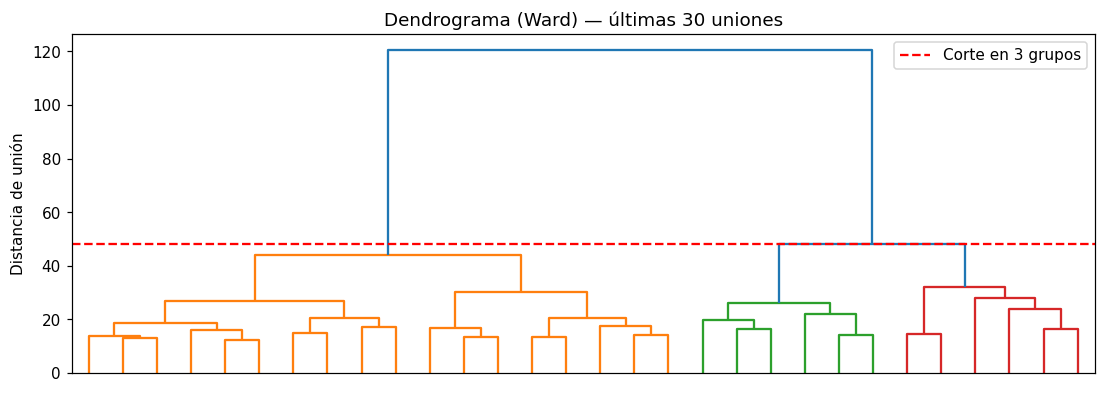

Silueta Ward (3 grupos): 0.216


,count
Cluster_ward,
H1,853
H2,372
H3,980


In [16]:
Z = linkage(Xz, method="ward")        # Ward usa distancia euclidiana internamente

plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=Z[-(K - 1), 2], no_labels=True)
plt.axhline(Z[-(K - 1), 2], color="red", ls="--", label="Corte en 3 grupos")
plt.title("Dendrograma (Ward) — últimas 30 uniones"); plt.ylabel("Distancia de unión"); plt.legend(); plt.show()

ward = fcluster(Z, t=K, criterion="maxclust")
orden_w = clientes.groupby(ward)["gasto_total"].mean().sort_values().index
clientes["Cluster_ward"] = pd.Series(ward).map({o: f"H{i+1}" for i, o in enumerate(orden_w)}).values
print(f"Silueta Ward (3 grupos): {silhouette_score(Xz, ward):.3f}")
clientes["Cluster_ward"].value_counts().sort_index()

### 3.2 DBSCAN — elegir `eps` con la distancia al k-ésimo vecino
**Cómo funciona:** un cliente es "núcleo" si tiene al menos `min_samples` vecinos a distancia ≤ `eps`. Los núcleos conectados forman un grupo; lo que no alcanza a ningún grupo es **ruido (−1)**. No hay que decirle cuántos grupos quiere.

**Gráfico de k-distancia:** para cada cliente se mide la distancia a su k-ésimo vecino más cercano y se ordenan de menor a mayor. Donde la curva "se dispara" (el codo) es un buen `eps`: por debajo, los puntos están en zonas densas; por encima, son aislados.

`MIN_VECINOS = 5` (igual que en la Parte 5). Con 9 variables, una regla común es usar más (≈ 2 × nº de variables = 18); puede probarlo después.

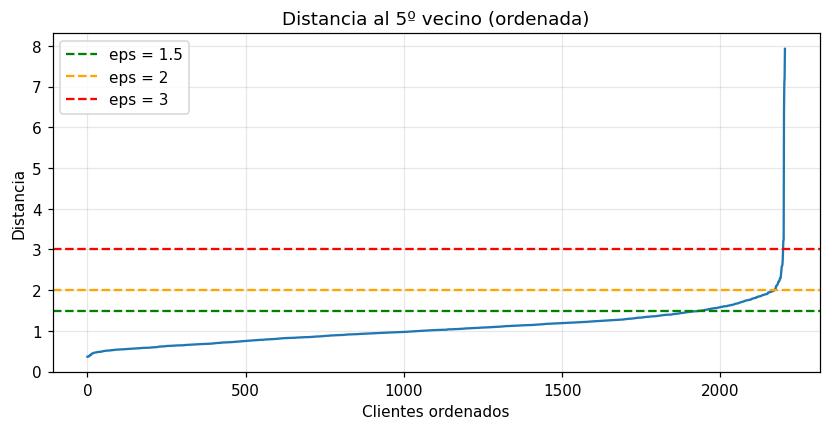

In [17]:
MIN_VECINOS = 5
dist, _ = NearestNeighbors(n_neighbors=MIN_VECINOS).fit(Xz).kneighbors(Xz)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(kdist)
for e, col in [(1.5, "green"), (2, "orange"), (3, "red")]:
    plt.axhline(e, ls="--", color=col, label=f"eps = {e}")
plt.title(f"Distancia al {MIN_VECINOS}º vecino (ordenada)"); plt.xlabel("Clientes ordenados"); plt.ylabel("Distancia")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [18]:
def resumen_dbscan(eps, datos=Xz, min_s=MIN_VECINOS):
    lab = DBSCAN(eps=eps, min_samples=min_s).fit_predict(datos)
    grupos = sorted(set(lab) - {-1})
    tam = pd.Series(lab).value_counts()
    return lab, {"eps": eps, "n_grupos": len(grupos), "ruido": int((lab == -1).sum()),
                 "% ruido": (lab == -1).mean(), "tamaños": [int(tam[g]) for g in grupos]}

filas, etiquetas_db = [], {}
for eps in [1.0, 1.5, 2.0, 2.5, 3.0]:
    lab, fila = resumen_dbscan(eps)
    etiquetas_db[eps] = lab; filas.append(fila)
display(pd.DataFrame(filas).style.format({"% ruido": "{:.1%}"}))

EPS_ELEGIDO = 1.5
lab = etiquetas_db[EPS_ELEGIDO]
clientes["Cluster_dbscan"] = np.where(lab == -1, "Ruido", "D" + (lab + 1).astype(str))

,eps,n_grupos,ruido,% ruido,tamaños
0,1.000000,28,860,39.0%,"[758, 37, 372, 7, 19, 6, 5, 6, 6, 6, 10, 5, 9, 14, 14, 11, 7, 7, 5, 5, 4, 5, 5, 5, 1, 5, 5, 6]"
1,1.500000,3,143,6.5%,"[839, 1186, 37]"
2,2.000000,1,19,0.9%,[2186]
3,2.500000,1,9,0.4%,[2196]
4,3.000000,1,4,0.2%,[2201]


### 3.3 Comparar cuántos clientes caen en cada grupo — `Merge Data` / Scatter coloreado
- **Tamaños por técnica**.
- **Tabla cruzada k-means vs. Ward:** si las técnicas coinciden, cada fila tiene casi todo en una sola columna.
- **ARI (Adjusted Rand Index):** 1 = particiones idénticas, 0 = coincidencia al azar.

In [19]:
tamanos = pd.concat({
    "k-means": clientes["Cluster"].value_counts().sort_index(),
    "Ward": clientes["Cluster_ward"].value_counts().sort_index(),
    f"DBSCAN eps={EPS_ELEGIDO}": clientes["Cluster_dbscan"].value_counts().sort_index(),
}, axis=1)
display(tamanos)

display(pd.crosstab(clientes["Cluster"], clientes["Cluster_ward"], margins=True, margins_name="Total"))
print(f"ARI k-means vs Ward:   {adjusted_rand_score(clientes['Cluster'], clientes['Cluster_ward']):.2f}")
print(f"ARI k-means vs DBSCAN: {adjusted_rand_score(clientes['Cluster'], clientes['Cluster_dbscan']):.2f}")

,k-means,Ward,DBSCAN eps=1.5
C1,"1,013.00",NaN,NaN
C2,631.00,NaN,NaN
C3,561.00,NaN,NaN
H1,NaN,853.00,NaN
H2,NaN,372.00,NaN
H3,NaN,980.00,NaN
D1,NaN,NaN,839.00
D2,NaN,NaN,"1,186.00"
D3,NaN,NaN,37.00
Ruido,NaN,NaN,143.00


Cluster_ward,H1,H2,H3,Total
Cluster,,,,
C1,795,207,11,1013
C2,58,164,409,631
C3,0,1,560,561
Total,853,372,980,2205


ARI k-means vs Ward:   0.47
ARI k-means vs DBSCAN: 0.31


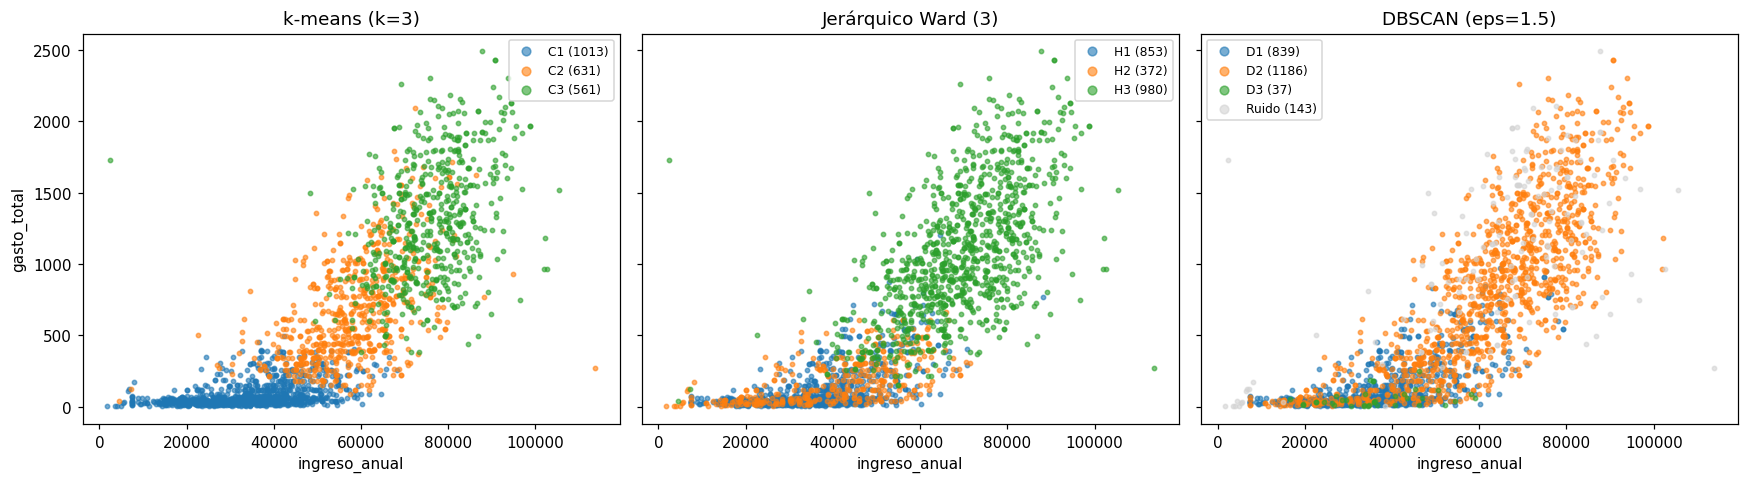

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, col, titulo in zip(axes, ["Cluster", "Cluster_ward", "Cluster_dbscan"],
                           ["k-means (k=3)", "Jerárquico Ward (3)", f"DBSCAN (eps={EPS_ELEGIDO})"]):
    for nombre in sorted(clientes[col].unique()):
        s = clientes[clientes[col] == nombre]
        ax.scatter(s["ingreso_anual"], s["gasto_total"], s=8, alpha=.6, label=f"{nombre} ({len(s)})",
                   color="lightgray" if nombre == "Ruido" else None)
    ax.set(title=titulo, xlabel="ingreso_anual"); ax.legend(fontsize=8, markerscale=2)
axes[0].set_ylabel("gasto_total"); plt.tight_layout(); plt.show()

✍️ **Respuestas Parte 3**

1. **¿Las tres técnicas dan los mismos grupos?**
No. k-means y Ward coinciden solo moderadamente (ARI = 0.47) y DBSCAN se parece poco a k-means (ARI = 0.31).
- **Coinciden en los extremos:** 560 de los 561 clientes de C3 (alto valor) caen en H3, y 795 de los 1,013 de C1 (bajo valor) caen en H1.
- **Difieren en el medio:** Ward manda 409 clientes de C2 al grupo de alto valor (H3 queda con 980 clientes) y parte a los de bajo gasto en dos: con hijos pequeños (H1, 853) y sin hijos y mayores (H2, 372).
- **DBSCAN (eps = 1.5)** forma 3 grupos (1,186 / 839 / 37) más 143 clientes de ruido (6.5 %). Sus grupos se separan sobre todo por el **número de hijos pequeños (0, 1, 2)**: como es una variable de pocos valores, crea "islas" de densidad artificiales, no segmentos de comportamiento.

2. **¿Qué pasa con DBSCAN al subir eps?**
Los grupos se fusionan. Con eps = 2 queda un solo grupo de 2,186 clientes (19 de ruido); con eps = 3, uno de 2,201 (4 de ruido). Los clientes forman una nube continua, sin huecos de baja densidad que los separen. Además, con eps = 1.5 los 143 clientes marcados como "ruido" son los que **más gastan** (1,100 en promedio vs. 563 del total): DBSCAN descartaría justamente a los mejores clientes.

3. **¿Cuál le serviría más a marketing para actuar?**
**k-means (k = 3)**:
- asigna a todos los clientes (sin "ruido" que nadie atiende);
- da grupos de tamaño manejable (1,013 / 631 / 561);
- muestra un gradiente claro de valor (gasto promedio 85 → 670 → 1,304);
- y el modelo guardado clasifica clientes nuevos, algo que Ward y DBSCAN no hacen directamente.

Limitación: la silueta (0.25) indica grupos que se traslapan. Es una partición útil para decidir, no grupos "naturales". Ward sería la alternativa si marketing quiere separar a las familias con hijos de los adultos mayores de bajo gasto.

## Parte 4 · ¿Cuánto vale cada segmento? (≈10 min)
**Orange:** `Group By` (conteo, promedio, suma) + `Formula` (porcentajes).

Calculamos por segmento: nº de clientes, gasto promedio, gasto total, **% de clientes**, **% del gasto**, y la **tasa de respuesta** a la última campaña.

Dos columnas extra que ayudan a decidir:
- **Índice de valor = % gasto ÷ % clientes.** > 1 significa que el segmento aporta más de lo que pesa en número.
- **Valor esperado por contacto (proxy) = tasa de respuesta × gasto promedio.** _Supuesto:_ usa el gasto histórico como aproximación del valor de un respondedor; no es margen ni CLV real.

In [21]:
valor = clientes.groupby("Cluster").agg(
    clientes=("gasto_total", "size"),
    gasto_promedio=("gasto_total", "mean"),
    gasto_total=("gasto_total", "sum"),
    ingreso_promedio=("ingreso_anual", "mean"),
    tasa_respuesta=("respondio_ultima_campana", "mean"),
    respondieron=("respondio_ultima_campana", "sum"),
)
valor["% clientes"]       = valor["clientes"] / valor["clientes"].sum()
valor["% gasto"]          = valor["gasto_total"] / valor["gasto_total"].sum()
valor["% respondedores"]  = valor["respondieron"] / valor["respondieron"].sum()
valor["indice_valor"]     = valor["% gasto"] / valor["% clientes"]
valor["valor_esp_contacto"] = valor["tasa_respuesta"] * valor["gasto_promedio"]

display(valor.style.format({
    "gasto_promedio": "{:,.0f}", "gasto_total": "{:,.0f}", "ingreso_promedio": "{:,.0f}",
    "tasa_respuesta": "{:.1%}", "respondieron": "{:,.0f}", "% clientes": "{:.1%}", "% gasto": "{:.1%}",
    "% respondedores": "{:.1%}", "indice_valor": "{:.2f}", "valor_esp_contacto": "{:,.0f}"}))

,clientes,gasto_promedio,gasto_total,ingreso_promedio,tasa_respuesta,respondieron,% clientes,% gasto,% respondedores,indice_valor,valor_esp_contacto
Cluster,,,,,,,,,,,
C1,1013,85,"86,496","33,986",10.3%,104,45.9%,7.0%,31.2%,0.15,9
C2,631,670,"423,002","58,159",13.8%,87,28.6%,34.1%,26.1%,1.19,92
C3,561,"1,304","731,398","76,116",25.3%,142,25.4%,58.9%,42.6%,2.32,330


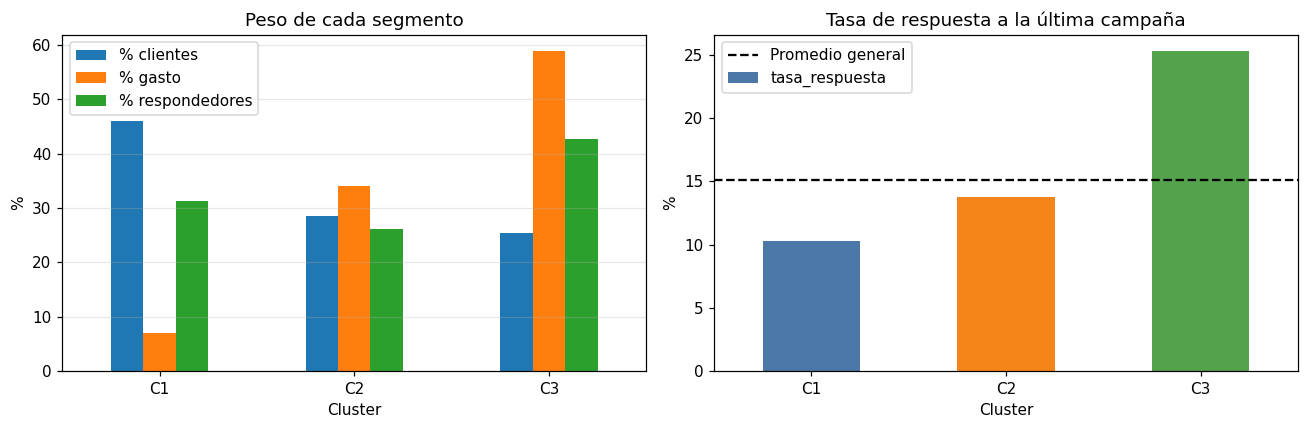

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
valor[["% clientes", "% gasto", "% respondedores"]].mul(100).plot.bar(ax=ax[0], rot=0)
ax[0].set(title="Peso de cada segmento", ylabel="%"); ax[0].grid(axis="y", alpha=.3)
valor["tasa_respuesta"].mul(100).plot.bar(ax=ax[1], rot=0, color=[COLORES[c] for c in valor.index])
ax[1].axhline(clientes["respondio_ultima_campana"].mean() * 100, ls="--", color="black", label="Promedio general")
ax[1].set(title="Tasa de respuesta a la última campaña", ylabel="%"); ax[1].legend()
plt.tight_layout(); plt.show()

✍️ **Respuestas Parte 4**

1. **¿Qué % de clientes genera qué % del gasto?**

| Segmento | % clientes | % gasto | Índice de valor | Tasa de respuesta | Valor esperado por contacto* |
|---|---|---|---|---|---|
| C1 · Familias jóvenes sensibles al precio | 45.9 % | 7.0 % | 0.15 | 10.3 % | 9 |
| C2 · Familias establecidas omnicanal | 28.6 % | 34.1 % | 1.19 | 13.8 % | 92 |
| C3 · Premium de alto valor por catálogo | 25.4 % | 58.9 % | 2.32 | 25.3 % | 330 |

- **C3 es una cuarta parte de los clientes y genera casi el 60 % del gasto**: cada cliente de C3 vale 2.3 veces su peso en número.
- **C2 + C3 (54 % de los clientes) generan el 93 % del gasto.** C1, casi la mitad de la base, aporta solo el 7 %.
- C3 también concentra el 43 % de todos los que respondieron a la última campaña.

*Valor esperado por contacto = tasa de respuesta × gasto promedio. Es un proxy: supone que el gasto histórico aproxima el valor de un respondedor; no es margen ni CLV real.

2. **¿A qué segmento le gastaría el presupuesto de la próxima campaña y por qué?**
**La mayor parte a C3, una parte relevante a C2 y un mínimo a C1.**

- **C3 (prioridad):** tiene el mayor valor esperado por contacto (330, 3.6 veces C2 y 38 veces C1). Si el costo por contacto (CAC) es similar entre segmentos, aquí está el mejor retorno. Como la recencia es casi igual en los tres grupos (46–52 días), la diferencia de CLV la explica casi por completo el gasto. **Tipo de campaña:** catálogo y productos premium, **no descuentos**, porque es el segmento que menos compra en oferta.
- **C2 (crecimiento):** valor medio pero buena base (631 clientes). Es el canal web más fuerte y el más orientado a ofertas, así que las promociones digitales tienen sentido. La oportunidad es mover clientes de C2 hacia C3.
- **C1 (mínimo):** cada respuesta vale muy poco (gasto promedio de 85). Visitan mucho la web pero no compran: el problema es de **conversión** (experiencia web, precio), no de alcance. Conviene atenderlo con canales de costo casi cero, no con presupuesto pagado.

**Advertencia crítica:** C3 ya aceptó en promedio 0.70 campañas anteriores (C1 solo 0.09). Su alta respuesta puede significar que **habrían comprado de todos modos**. Antes de asignarle todo el presupuesto, conviene medir el efecto incremental con un **grupo de control** (A/B): dejar un porcentaje de C3 sin campaña y comparar.

*Supuestos:* no tenemos margen ni CAC reales; asumo costo por contacto similar entre segmentos. El gasto es acumulado, así que parte de la diferencia podría deberse a la antigüedad del cliente.

### Guardar la segmentación — `Save Data` → `clientes_con_cluster.csv`
Se guarda la tabla original **+ la columna `Cluster`** (C1, C2, C3), igual que la salida de Orange. Las columnas de Ward y DBSCAN eran solo para comparar, no se incluyen.

Además se guarda el modelo (estandarizador + k-means) en `.joblib`; sirve para clasificar clientes nuevos y lo usa la app de Streamlit.

In [23]:
os.makedirs("outputs", exist_ok=True)
salida = clientes.drop(columns=["Cluster_ward", "Cluster_dbscan"])
salida.to_csv("outputs/clientes_con_cluster.csv", index=False)

# Comprobación (lo que pide la guía: abrirlo y ver la columna Cluster con C1, C2, C3)
check = pd.read_csv("outputs/clientes_con_cluster.csv")
assert "Cluster" in check.columns and set(check["Cluster"]) == {"C1", "C2", "C3"}
print("✔ Archivo correcto:", check.shape)
display(check["Cluster"].value_counts().sort_index())

modelo = Pipeline([("estandarizar", escalador), ("kmeans", km3)])
joblib.dump({"modelo": modelo, "atributos": ATRIBUTOS, "mapa_etiquetas": MAPA}, "outputs/modelo_kmeans_k3.joblib")
print("✔ Modelo guardado: outputs/modelo_kmeans_k3.joblib")

✔ Archivo correcto: (2205, 24)


,count
Cluster,
C1,1013
C2,631
C3,561


✔ Modelo guardado: outputs/modelo_kmeans_k3.joblib


In [24]:
# Solo en Colab: descargar los archivos a su computadora
try:
    from google.colab import files
    files.download("outputs/clientes_con_cluster.csv")
    files.download("outputs/modelo_kmeans_k3.joblib")
except ImportError:
    print("No está en Colab: los archivos quedaron en la carpeta outputs/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Parte 5 · Datos sintéticos: cuando k-means falla (≈10 min)
`formas_lunas.csv`: dos lunas entrelazadas + 20 puntos de ruido. Sabemos la respuesta correcta (`grupo_real`), así que podemos medir qué técnica acierta.

**No se estandariza**: x e y ya están en la misma escala, y los valores de eps de la guía (0.2 y 0.1) están pensados para las unidades originales.

In [25]:
lunas = limpiar_encabezados(pd.read_csv(RUTA["formas_lunas.csv"]))
print(lunas.shape); display(lunas.head())
display(lunas["grupo_real"].value_counts())
XY = lunas[["x", "y"]].values

(420, 3)


,x,y,grupo_real
0,0.50,-0.35,luna_B
1,0.51,0.88,luna_A
2,-0.33,0.96,luna_A
3,-0.55,0.92,luna_A
4,1.97,0.23,luna_B


,count
grupo_real,
luna_B,200
luna_A,200
ruido,20


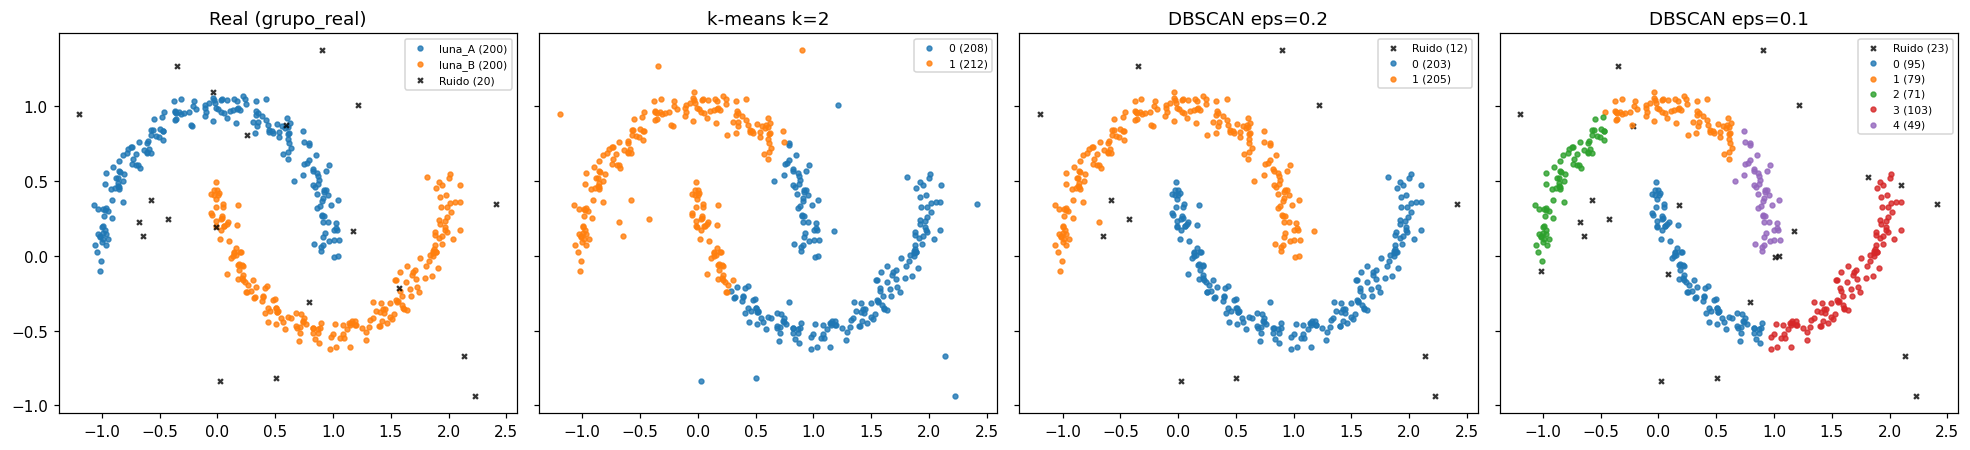

k-means k=2        ARI vs real = 0.23 | grupos = 2 | ruido = 0
DBSCAN eps=0.2     ARI vs real = 0.96 | grupos = 2 | ruido = 12
DBSCAN eps=0.1     ARI vs real = 0.41 | grupos = 5 | ruido = 23


In [26]:
pred = {"Real (grupo_real)": lunas["grupo_real"].astype(str).values}
pred["k-means k=2"] = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA).fit_predict(XY).astype(str)
for eps in [0.2, 0.1]:
    pred[f"DBSCAN eps={eps}"] = DBSCAN(eps=eps, min_samples=5).fit_predict(XY).astype(str)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharex=True, sharey=True)
for ax, (titulo, lab) in zip(axes, pred.items()):
    for v in sorted(set(lab)):
        m = lab == v
        es_ruido = v in ("-1", "ruido", "Ruido", "noise")
        ax.scatter(XY[m, 0], XY[m, 1], s=10, alpha=.8, label=("Ruido" if es_ruido else v) + f" ({m.sum()})",
                   color="black" if es_ruido else None, marker="x" if es_ruido else "o")
    ax.set_title(titulo); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

real = pred["Real (grupo_real)"]
for titulo, lab in list(pred.items())[1:]:
    print(f"{titulo:18s} ARI vs real = {adjusted_rand_score(real, lab):.2f} | grupos = {len(set(lab) - {'-1'})} | "
          f"ruido = {(lab == '-1').sum()}")

✍️ **Respuestas Parte 5**

1. **¿Por qué k-means corta mal?**
k-means asigna cada punto al centro más cercano. Por eso siempre divide el espacio con una **línea recta** entre los dos centros y supone grupos redondos ("bolas") de tamaño parecido. Las lunas son curvas y están entrelazadas: la punta de cada luna queda más cerca del centro de la otra.
Resultado: clasifica mal unos 100 de los 400 puntos de las lunas (49 de luna A y 50 de luna B, ≈25 %), y su ARI contra el grupo real es de solo **0.23**. Además, como k-means no tiene el concepto de ruido, reparte los 20 puntos de ruido entre los dos grupos.

2. **¿Qué hizo DBSCAN con el ruido?**
- **eps = 0.2:** sigue la forma de las lunas por densidad y las separa **perfectamente** (los 400 puntos bien asignados, ARI = **0.96**). Marca como ruido (−1) 12 de los 20 puntos aislados. Los otros 8 los absorbe porque quedaron cerca de alguna luna.
- **eps = 0.1:** el vecindario es demasiado pequeño. Parte la luna A en 3 pedazos y la luna B en 2 (5 grupos en total), marca como ruido 8 puntos que sí pertenecían a las lunas y el ARI cae a **0.41**.

Moraleja: DBSCAN encuentra formas que k-means no puede ver, pero es **muy sensible a eps**. Hay que elegirlo con el gráfico de distancia al k-ésimo vecino, no al azar.

3. **¿Cuándo sospecharía que sus clientes no tienen forma de "bolas"?**
Señales de alerta:
- silueta baja con cualquier k;
- un scatter con formas alargadas, curvas o con densidades muy distintas;
- resultados de k-means que cambian al cambiar la semilla;
- variables muy sesgadas o con pocos valores posibles.

**En nuestros clientes aparecen varias:** la silueta es baja (0.34 con k=2 y 0.25 con k=3); DBSCAN con eps ≥ 2 junta a casi todos en una sola nube; `gasto_total` está sesgado (media 563 vs. mediana 343); y `hijos_pequenos` (valores 0, 1, 2) crea "islas" artificiales de densidad. Conclusión: los clientes no forman bolas separadas, sino un continuo. k-means sirve como partición práctica, pero conviene probar transformar las variables sesgadas (logaritmo) y usar **mezclas gaussianas**, que permiten grupos elípticos y asignación probabilística (notebook de la tarea).

## Cierre — recomendación a marketing (3 líneas)

1. Recomiendo segmentar con **k-means, k = 3**, sobre las 9 variables estandarizadas: asigna a todos los clientes (DBSCAN dejaba como "ruido" justamente a los que más gastan), da perfiles claros y el modelo guardado clasifica clientes nuevos.
2. **C3 · Premium por catálogo** concentra el **59 % del gasto con el 25 % de los clientes** y responde 2.5 veces más que C1: recibe la mayor parte del presupuesto, con campañas premium **sin descuento**. **C2 · Omnicanal** (34 % del gasto) se trabaja con ofertas web, y **C1 · Familias sensibles al precio** (46 % de los clientes, solo 7 % del gasto) con mejoras de conversión web de bajo costo.
3. La silueta (0.25) indica grupos que se traslapan: hay que tratarlos como una **partición de negocio**, no como grupos naturales, y validar la campaña en C3 con un **grupo de control**, porque sus clientes ya aceptan campañas anteriores y podrían comprar de todos modos.